# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [14]:
ROLL_NO = 1024170453          # <-- your full roll number
NAME = "Muskan Kohli"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [15]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [16]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [17]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170453   Name: Muskan Kohli   Fingerprint: 19B26A93   Tickets: 15

Ticket_ID                                                                                    Ticket_Text
      T01                                 Password crashes while opening during the lab. This is urgent.
      T02                               I reinstalled the Wi-Fi on my laptop. I don't know what changed.
      T03                                                   Call me on +91 98765 43210 or 0175-239-3201.
      T04                                I was locked out of the laptop on my laptop. Please resolve it.
      T05                                I tried restarting the e-mail on my laptop. Can you check this?
      T06                               I reinstalled the lms during the lab. I don't know what changed.
      T07                                                                  Version 2.0.1 crashes at 99%.
      T08                      Wi-Fi has stopped syncing when connected to c

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [18]:
results = []

for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    result = process_ticket(row["Ticket_Text"])

    results.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

preprocessing_df = pd.DataFrame(results)

total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": preprocessing_df["Sentences"].sum(),
    "Tokens": preprocessing_df["Tokens"].sum(),
    "Punctuation Tokens": preprocessing_df["Punctuation Tokens"].sum(),
    "Stopwords": preprocessing_df["Stopwords"].sum(),
    "Unique Tokens": preprocessing_df["Unique Tokens"].sum(),
    "Final Tokens": preprocessing_df["Final Tokens"].sum()
}

preprocessing_df = pd.concat(
    [preprocessing_df, pd.DataFrame([total_row])],
    ignore_index=True
)

display(preprocessing_df)


selected_ticket = df.iloc[0]
selected_result = process_ticket(selected_ticket["Ticket_Text"])

print("\nSelected Ticket:", selected_ticket["Ticket_ID"])
print("Ticket Text:", selected_ticket["Ticket_Text"])
print("Tokens:", selected_result["tokens"])
print("Punctuation Tokens:", selected_result["punct"])
print("Stopwords:", selected_result["stops"])
print("Final Tokens:", selected_result["final"])


,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,12,2,5,11,5
1,T02,2,15,2,7,13,6
2,T03,1,9,1,3,9,5
3,T04,2,15,2,8,13,5
4,T05,2,14,2,7,14,5
5,T06,2,15,2,7,12,6
6,T07,1,7,2,1,7,4
7,T08,2,14,2,5,12,7
8,T09,2,10,4,3,8,3
9,T10,1,10,2,4,9,4



Selected Ticket: T01
Ticket Text: Password crashes while opening during the lab. This is urgent.
Tokens: ['password', 'crashes', 'while', 'opening', 'during', 'the', 'lab', '.', 'this', 'is', 'urgent', '.']
Punctuation Tokens: ['.', '.']
Stopwords: ['while', 'during', 'the', 'this', 'is']
Final Tokens: ['password', 'crashes', 'opening', 'lab', 'urgent']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [19]:

import re

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

url_pattern = (
    r"(?:https?://|www\.)"
    r"[A-Za-z0-9.-]+"
    r"(?:/[^\s<>\"']*)?"
)

phone_pattern = (
    r"(?<!\w)(?:\+91[\s-]?\d{5}[\s-]?\d{5}"
    r"|\+91-\d{5}-\d{5}"
    r"|\d{4}-\d{3}-\d{4}"
    r"|\d{10})(?!\w)"
)

long_word_pattern = r"\b[A-Za-z]{6,}\b"
number_pattern = r"\b(?:0x[0-9A-Fa-f]+|\d+(?:\.\d+)+|\d[\d,]*)\b"
capitalized_pattern = r"\b[A-Z][A-Za-z]*\b"
vowel_word_pattern = r"\b[AEIOUaeiou][A-Za-z]*\b"

for _, row in df.iterrows():
    text = row["Ticket_Text"]

    print("\n", row["Ticket_ID"], ":", text)
    print("Words longer than 5 letters:",
          re.findall(long_word_pattern, text))
    print("Numbers:",
          re.findall(number_pattern, text))
    print("Capitalized words:",
          re.findall(capitalized_pattern, text))
    print("Words beginning with a vowel:",
          re.findall(vowel_word_pattern, text))

print("\n--- TEST_LINES ---")

for line in TEST_LINES:
    print("\nOriginal:", line)
    print("Long words:", re.findall(long_word_pattern, line))
    print("Numbers:", re.findall(number_pattern, line))
    print("Capitalized:", re.findall(capitalized_pattern, line))
    print("Vowel words:", re.findall(vowel_word_pattern, line))

    cleaned = re.sub(email_pattern, "<EMAIL>", line)
    cleaned = re.sub(url_pattern, "<URL>", cleaned)
    cleaned = re.sub(phone_pattern, "<PHONE>", cleaned)

    print("After replacement:", cleaned)

print("\n--- REPLACED TICKETS ---")

for _, row in df.iterrows():
    cleaned = row["Ticket_Text"]
    cleaned = re.sub(email_pattern, "<EMAIL>", cleaned)
    cleaned = re.sub(url_pattern, "<URL>", cleaned)
    cleaned = re.sub(phone_pattern, "<PHONE>", cleaned)
    print(row["Ticket_ID"], ":", cleaned)



 T01 : Password crashes while opening during the lab. This is urgent.
Words longer than 5 letters: ['Password', 'crashes', 'opening', 'during', 'urgent']
Numbers: []
Capitalized words: ['Password', 'This']
Words beginning with a vowel: ['opening', 'is', 'urgent']

 T02 : I reinstalled the Wi-Fi on my laptop. I don't know what changed.
Words longer than 5 letters: ['reinstalled', 'laptop', 'changed']
Numbers: []
Capitalized words: ['I', 'Wi', 'Fi', 'I']
Words beginning with a vowel: ['I', 'on', 'I']

 T03 : Call me on +91 98765 43210 or 0175-239-3201.
Words longer than 5 letters: []
Numbers: ['91', '98765', '43210', '0175', '239', '3201']
Capitalized words: ['Call']
Words beginning with a vowel: ['on', 'or']

 T04 : I was locked out of the laptop on my laptop. Please resolve it.
Words longer than 5 letters: ['locked', 'laptop', 'laptop', 'Please', 'resolve']
Numbers: []
Capitalized words: ['I', 'Please']
Words beginning with a vowel: ['I', 'out', 'of', 'on', 'it']

 T05 : I tried resta

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [20]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

token_pattern = (
    r"https?://[^\s<>\"']+|www\.[^\s<>\"']+"
    r"|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
    r"|\+91[\s-]?\d{5}[\s-]?\d{5}"
    r"|\d{4}-\d{3}-\d{4}"
    r"|\d{10}"
    r"|\b\d+(?:\.\d+)+\b"
    r"|\b\d[\d,]*\b"
    r"|\b[A-Za-z]+(?:-[A-Za-z]+)+\b"
    r"|\b[A-Za-z]+(?:['’][A-Za-z]+)+\b"
    r"|[A-Za-z]+"
    r"|[^\w\s]"
)

custom_tokenizer = RegexpTokenizer(token_pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("--- TEST_LINES COMPARISON ---")

for i, line in enumerate(TEST_LINES, start=1):
    print("\nLine", i)
    print("Custom tokenizer:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

print("\n--- TICKET COMPARISON ---")

different_tickets = []

for _, row in df.iterrows():
    text = row["Ticket_Text"]
    custom = my_tokenize(text)
    standard = word_tokenize(text)

    if custom != standard:
        different_tickets.append(row["Ticket_ID"])

    print("\n", row["Ticket_ID"])
    print("Custom:", custom)
    print("Standard:", standard)

print("\nTickets with different tokenization:",
      len(different_tickets))
print("Ticket IDs:", different_tickets)
print("Total tickets:", len(df))


--- TEST_LINES COMPARISON ---

Line 1
Custom tokenizer: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Line 2
Custom tokenizer: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Line 3
Custom tokenizer: ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
word_tokenize: ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [21]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()
wordnet_lemmatizer = WordNetLemmatizer()

unique_final_tokens = sorted({
    token
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["final"]
})

if any(word.endswith("ing") and len(word) > 4
       for word in unique_final_tokens):
    suffix = "ing$"
    suffix_examples = [
        word for word in unique_final_tokens
        if word.endswith("ing") and len(word) > 4
    ]
elif any(word.endswith("ed") and len(word) > 4
         for word in unique_final_tokens):
    suffix = "ed$"
    suffix_examples = [
        word for word in unique_final_tokens
        if word.endswith("ed") and len(word) > 4
    ]
else:
    suffix = "s$"
    suffix_examples = [
        word for word in unique_final_tokens
        if word.endswith("s") and len(word) > 3
    ]

regexp_stemmer = RegexpStemmer(suffix, min=4)

tagged_words = pos_tag(unique_final_tokens)

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    return "n"

comparison = []

for word, tag in tagged_words:
    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)
    lemma_result = wordnet_lemmatizer.lemmatize(
        word, get_wordnet_pos(tag)
    )

    comparison.append({
        "Word": word,
        "Porter": porter_result,
        "Lancaster": lancaster_result,
        "Regexp": regexp_result,
        "POS Lemma": lemma_result
    })

comparison_df = pd.DataFrame(comparison)

different_outputs = comparison_df[
    comparison_df[["Porter", "Lancaster", "Regexp", "POS Lemma"]]
    .nunique(axis=1) > 1
].reset_index(drop=True)

print("Regexp suffix rule:", suffix)
print("Examples supporting suffix choice:", suffix_examples[:10])
display(different_outputs)

print("\nTotal unique final tokens:", len(unique_final_tokens))
print("Words with differing outputs:", len(different_outputs))


Regexp suffix rule: ing$
Examples supporting suffix choice: ['asking', 'getting', 'opening', 'responding', 'restarting', 'syncing']


,Word,Porter,Lancaster,Regexp,POS Lemma
0,another,anoth,anoth,another,another
1,call,call,cal,call,call
2,campus,campu,camp,campus,campus
3,changed,chang,chang,changed,change
4,computer,comput,comput,computer,computer
5,connected,connect,connect,connected,connect
6,crashes,crash,crash,crashes,crash
7,getting,get,get,gett,get
8,keeps,keep,keep,keeps,keep
9,latest,latest,latest,latest,late



Total unique final tokens: 56
Words with differing outputs: 33


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1: All tokens,193,91,0.4715
1,S2: Without punctuation,162,85,0.5247
2,S3: Final tokens,86,56,0.6512
3,S4: Porter-stemmed final tokens,86,54,0.6279



Top 10 words in S1:
[('.', 21), ('the', 14), ('i', 10), ('on', 5), ("n't", 5), ('this', 4), ('is', 4), ('wi-fi', 4), ('laptop', 4), ('?', 4)]

Top 10 words in S3:
[("n't", 5), ('wi-fi', 4), ('laptop', 4), ('crashes', 3), ('know', 3), ('changed', 3), ('another', 3), ('password', 2), ('opening', 2), ('lab', 2)]


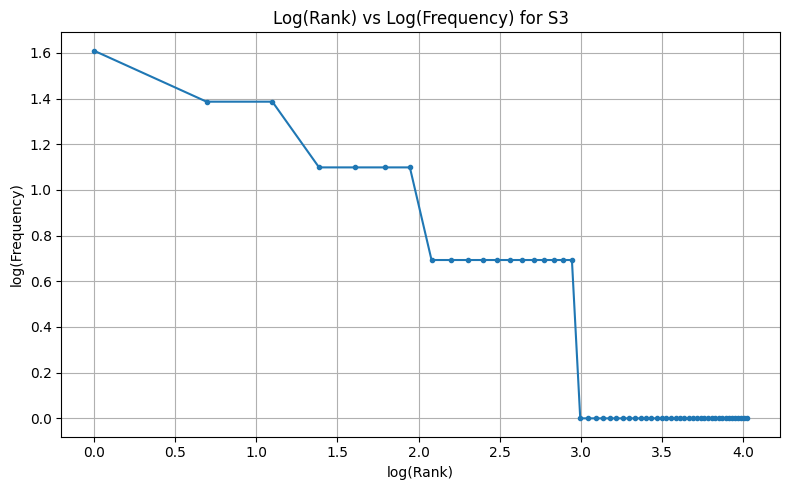


Top 5 bigrams in S1:
[(('.', 'i'), 7), (('on', 'my'), 3), (('my', 'laptop'), 3), (('laptop', '.'), 3), (('i', 'do'), 3)]

Top 5 bigrams in S3:
[(("n't", 'know'), 3), (('know', 'changed'), 3), (('crashes', 'opening'), 2), (('another', 'solution'), 2), (('latest', 'update'), 2)]


In [22]:
import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import bigrams

S1 = [
    token
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["tokens"]
]

S2 = [
    token for token in S1
    if not is_punct(token)
]

S3 = [
    token
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["final"]
]

S4 = [porter.stem(token) for token in S3]

corpora = {
    "S1: All tokens": S1,
    "S2: Without punctuation": S2,
    "S3: Final tokens": S3,
    "S4: Porter-stemmed final tokens": S4
}

stats = []

for name, corpus in corpora.items():
    total = len(corpus)
    unique = len(set(corpus))
    ttr = unique / total if total else 0

    stats.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

stats_df = pd.DataFrame(stats)
display(stats_df)

print("\nTop 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))

frequencies = sorted(Counter(S3).values(), reverse=True)

ranks = list(range(1, len(frequencies) + 1))
log_ranks = [math.log(rank) for rank in ranks]
log_frequencies = [math.log(freq) for freq in frequencies]

plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_frequencies, marker="o", markersize=3)
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nTop 5 bigrams in S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams in S3:")
print(Counter(bigrams(S3)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*